# The Johnson-Lindenstrauss bound for embedding with random projections: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/miscellaneous/plot_johnson_lindenstrauss_bound.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/miscellaneous/plot_johnson_lindenstrauss_bound.html)).

**Scenario:** the vectorised `johnson_lindenstrauss_min_dim` bound curves (array `n_samples` with scalar `eps`, then
scalar `n_samples` with array `eps`), followed by `SparseRandomProjection(n_components=k)` embeddings for
`k in (300, 1000, 10000)` and the distribution of pairwise squared-distance rates (projected / original).

**Adaptations:**
- Data: the example's own offline switch `--use-digits-dataset` (`load_digits().data[:300]`, dense, 64 features)
  replaces the downloaded 20 newsgroups data. Because the newsgroups path feeds CSR input, section 3 repeats the
  projection on a CSR copy of the digits so the sparse-input / sparse-output path is exercised as well.
- `random_state=0` is added to `SparseRandomProjection`. The example leaves it unset, so its output depends on
  NumPy's global entropy; with a fixed seed Moxie's native legacy-MT19937 sampling reproduces the exact matrix.
- With 64 features every `k` is an expansion; sklearn emits `DataDimensionalityWarning`, Moxie does not emit
  warnings (documented in `docs/random_projection/api.md`, *Explicit native limits*). The expansion itself works.
- Only the `k=300` and `k=10000` rate histograms are drawn (small figures); all three are compared numerically.
- Section 4 (beyond the example) checks `inverse_transform` / `inverse_components_` on the same data.

**Determinism:** deterministic once `random_state=0` is fixed (single-threaded sampling, no races). Components are
compared exactly (same draws, same scale constant); projections and distances use tolerances explained below.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("random_projection/plot_johnson_lindenstrauss_bound")

## 1. scikit-learn (Python reference)

The example code with the digits switch and `random_state=0`.

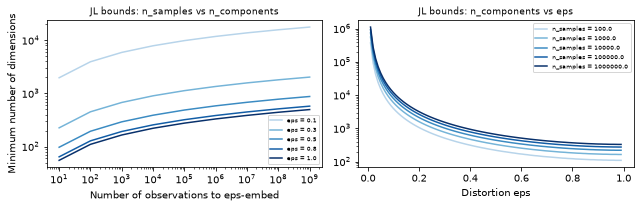

Embedding 300 samples with dim 64 using various random projections
Projected 300 samples from 64 to 300 in 0.002s
Random matrix with size: 0.029 MB
Mean distances rate: 1.02 (0.08)
Projected 300 samples from 64 to 1000 in 0.009s
Random matrix with size: 0.095 MB
Mean distances rate: 1.00 (0.05)
Projected 300 samples from 64 to 10000 in 0.044s
Random matrix with size: 0.955 MB
Mean distances rate: 0.99 (0.01)
warnings: {np.int64(300): ['DataDimensionalityWarning'], np.int64(1000): ['DataDimensionalityWarning'], np.int64(10000): ['DataDimensionalityWarning']}


In [2]:
import warnings
from time import time

import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse

from sklearn.datasets import load_digits
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.random_projection import (
    GaussianRandomProjection,
    SparseRandomProjection,
    johnson_lindenstrauss_min_dim,
)

# range of admissible distortions
eps_range = np.linspace(0.1, 0.99, 5)
colors = plt.cm.Blues(np.linspace(0.3, 1.0, len(eps_range)))
# range of number of samples (observation) to embed
n_samples_range = np.logspace(1, 9, 9)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), dpi=72)
sk_bounds_by_eps = []
for eps, color in zip(eps_range, colors):
    min_n_components = johnson_lindenstrauss_min_dim(n_samples_range, eps=eps)
    sk_bounds_by_eps.append(min_n_components)
    axes[0].loglog(n_samples_range, min_n_components, color=color)
axes[0].legend([f"eps = {eps:0.1f}" for eps in eps_range], loc="lower right", fontsize=6)
axes[0].set_xlabel("Number of observations to eps-embed")
axes[0].set_ylabel("Minimum number of dimensions")
axes[0].set_title("JL bounds: n_samples vs n_components", fontsize=9)

eps_range2 = np.linspace(0.01, 0.99, 100)
n_samples_range2 = np.logspace(2, 6, 5)
colors = plt.cm.Blues(np.linspace(0.3, 1.0, len(n_samples_range2)))
sk_bounds_by_n = []
for n_samples, color in zip(n_samples_range2, colors):
    min_n_components = johnson_lindenstrauss_min_dim(n_samples, eps=eps_range2)
    sk_bounds_by_n.append(min_n_components)
    axes[1].semilogy(eps_range2, min_n_components, color=color)
axes[1].legend([f"n_samples = {n}" for n in n_samples_range2], loc="upper right", fontsize=6)
axes[1].set_xlabel("Distortion eps")
axes[1].set_title("JL bounds: n_components vs eps", fontsize=9)
plt.tight_layout(); plt.show()

data = load_digits().data[:300]
n_samples, n_features = data.shape
print(f"Embedding {n_samples} samples with dim {n_features} using various random projections")

n_components_range = np.array([300, 1_000, 10_000])
dists = euclidean_distances(data, squared=True).ravel()
nonzero = dists != 0
dists = dists[nonzero]

sk_projected, sk_components, sk_rates, sk_warnings = {}, {}, {}, {}
for n_components in n_components_range:
    t0 = time()
    rp = SparseRandomProjection(n_components=n_components, random_state=0)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        projected_data = rp.fit_transform(data)
    sk_warnings[n_components] = [type(w.message).__name__ for w in caught]
    print(f"Projected {n_samples} samples from {n_features} to {n_components} in {time() - t0:0.3f}s")
    n_bytes = rp.components_.data.nbytes
    n_bytes += rp.components_.indices.nbytes
    print(f"Random matrix with size: {n_bytes / 1e6:0.3f} MB")
    projected_dists = euclidean_distances(projected_data, squared=True).ravel()[nonzero]
    rates = projected_dists / dists
    print(f"Mean distances rate: {np.mean(rates):.2f} ({np.std(rates):.2f})")
    sk_projected[n_components] = projected_data
    sk_components[n_components] = rp.components_.toarray()
    sk_rates[n_components] = rates
sk_density = rp.density_
print("warnings:", sk_warnings)
nb.share(data=data, n_samples_range=n_samples_range, eps_range=eps_range,
         n_samples_range2=n_samples_range2, eps_range2=eps_range2)

## 2. Moxie (native Mojo)

The same bounds and embeddings through `moxie.random_projection`. NDArray data is copied into the family's `ProjectionMatrix` storage (see GAP notes: the estimators do not accept NDArray directly).

In [3]:
%%mojo jl_bound
from numojo import NDArray, Shape, zeros
from moxie.random_projection import SparseRandomProjection, ProjectionMatrix, johnson_lindenstrauss_min_dim
from moxie_nb_io import load, save, save_ints, save_floats

def to_projection(x: NDArray[DType.float64]) raises -> ProjectionMatrix[DType.float64]:
    var values = List[Float64]()
    for k in range(x.size):
        values.append(x.unsafe_get(k))
    return ProjectionMatrix(x.shape[0], x.shape[1], values^)


def to_ndarray(m: ProjectionMatrix[DType.float64]) raises -> NDArray[DType.float64]:
    var dense = m.to_dense()
    var out = zeros[DType.float64](Shape(dense.rows, dense.cols))
    for k in range(len(dense.data)):
        out.unsafe_set(k, dense.data[k])
    return out^


def floats(x: NDArray[DType.float64]) -> List[Float64]:
    var out = List[Float64]()
    for k in range(x.size):
        out.append(x.unsafe_get(k))
    return out^


def main() raises:
    # Vectorised bound: array n_samples, scalar eps; then scalar n_samples, array eps.
    var by_eps = List[Int]()
    var eps_range = floats(load("eps_range"))
    for eps in eps_range:
        by_eps.extend(johnson_lindenstrauss_min_dim(floats(load("n_samples_range")), eps=eps))
    save_ints("bounds_by_eps", by_eps)
    var by_n = List[Int]()
    for n in floats(load("n_samples_range2")):
        by_n.extend(johnson_lindenstrauss_min_dim(n, eps=floats(load("eps_range2"))))
    save_ints("bounds_by_n", by_n)

    var data = to_projection(load("data"))
    var ks: List[Int] = [300, 1000, 10000]
    for k in ks:
        var rp = SparseRandomProjection(n_components=k, random_state=0)
        var projected = rp.fit_transform(data)
        print("Projected", data.rows, "samples from", data.cols, "to", k,
              "| nnz:", len(rp.components_.data), "| sparse output:", projected.is_sparse)
        save("projected_" + String(k), to_ndarray(projected))
        save("components_" + String(k), to_ndarray(rp.components_))
        if k == 10000:
            save_floats("density", [rp.density_])
            save_ints("shape", [rp.n_components_, rp.n_features_in_])

Projected 300 samples from 64 to 300 | nnz: 2414 | sparse output: False
Projected 300 samples from 64 to 1000 | nnz: 7938 | sparse output: False
Projected 300 samples from 64 to 10000 | nnz: 79618 | sparse output: False


## 3. CSR input (the example's default newsgroups path is sparse)

sklearn returns a sparse matrix when input and components are sparse and `dense_output=False`; Moxie returns CSR storage under the same rule.

In [4]:
X_csr = sparse.csr_matrix(data)
csr_rp = SparseRandomProjection(n_components=300, random_state=0)
sk_csr_out = csr_rp.fit_transform(X_csr)
sk_csr_dense_rp = SparseRandomProjection(n_components=300, random_state=0, dense_output=True)
sk_csr_dense_out = sk_csr_dense_rp.fit_transform(X_csr)
print(type(sk_csr_out).__name__, type(sk_csr_dense_out).__name__)
nb.share(csr_data=X_csr.data, csr_indices=X_csr.indices.astype(np.float64), csr_indptr=X_csr.indptr.astype(np.float64))

csr_matrix ndarray


/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/random_projection.py:412: DataDimensionalityWarning: The number of components is higher than the number of features: n_features < n_components (64 < 300).The dimensionality of the problem will not be reduced.
  warnings.warn(


In [5]:
%%mojo jl_csr
from numojo import NDArray, Shape, zeros
from moxie.random_projection import SparseRandomProjection, ProjectionMatrix
from moxie_nb_io import load, save, save_ints

def to_projection(x: NDArray[DType.float64]) raises -> ProjectionMatrix[DType.float64]:
    var values = List[Float64]()
    for k in range(x.size):
        values.append(x.unsafe_get(k))
    return ProjectionMatrix(x.shape[0], x.shape[1], values^)


def to_ndarray(m: ProjectionMatrix[DType.float64]) raises -> NDArray[DType.float64]:
    var dense = m.to_dense()
    var out = zeros[DType.float64](Shape(dense.rows, dense.cols))
    for k in range(len(dense.data)):
        out.unsafe_set(k, dense.data[k])
    return out^


def ints(x: NDArray[DType.float64]) -> List[Int]:
    var out = List[Int]()
    for k in range(x.size):
        out.append(Int(x.unsafe_get(k)))
    return out^


def main() raises:
    var values = load("csr_data")
    var data = List[Float64]()
    for k in range(values.size):
        data.append(values.unsafe_get(k))
    var X = ProjectionMatrix[DType.float64].from_csr(300, 64, data^, ints(load("csr_indices")), ints(load("csr_indptr")))
    var rp = SparseRandomProjection(n_components=300, random_state=0)
    var out = rp.fit_transform(X)
    var dense_rp = SparseRandomProjection(n_components=300, random_state=0, dense_output=True)
    var dense_out = dense_rp.fit_transform(X)
    print("sparse output:", out.is_sparse, "| dense_output=True gives sparse:", dense_out.is_sparse)
    save_ints("is_sparse", [Int(out.is_sparse), Int(dense_out.is_sparse)])
    save("csr_out", to_ndarray(out))
    save("csr_dense_out", to_ndarray(dense_out))

sparse output: True | dense_output=True gives sparse: False


## 4. Beyond the example: `inverse_transform` and `compute_inverse_components`

Both estimators on the same digits; the inverse is the Moore-Penrose pseudoinverse of the components.

In [6]:
g = GaussianRandomProjection(n_components=30, compute_inverse_components=True, random_state=0).fit(data)
sk_g_components = g.components_
sk_g_inverse = g.inverse_components_
sk_g_projected = g.transform(data)
sk_g_back = g.inverse_transform(sk_g_projected)
s = SparseRandomProjection(n_components=30, random_state=0).fit(data)
sk_s_back = s.inverse_transform(s.transform(data))
sk_names = list(g.get_feature_names_out()[:3]) + list(s.get_feature_names_out()[-2:])
print(sk_names)

['gaussianrandomprojection0', 'gaussianrandomprojection1', 'gaussianrandomprojection2', 'sparserandomprojection28', 'sparserandomprojection29']


In [7]:
%%mojo jl_inverse
from numojo import NDArray, Shape, zeros
from moxie.random_projection import GaussianRandomProjection, SparseRandomProjection, ProjectionMatrix
from moxie_nb_io import load, save, save_strings

def to_projection(x: NDArray[DType.float64]) raises -> ProjectionMatrix[DType.float64]:
    var values = List[Float64]()
    for k in range(x.size):
        values.append(x.unsafe_get(k))
    return ProjectionMatrix(x.shape[0], x.shape[1], values^)


def to_ndarray(m: ProjectionMatrix[DType.float64]) raises -> NDArray[DType.float64]:
    var dense = m.to_dense()
    var out = zeros[DType.float64](Shape(dense.rows, dense.cols))
    for k in range(len(dense.data)):
        out.unsafe_set(k, dense.data[k])
    return out^


def main() raises:
    var data = to_projection(load("data"))
    var g = GaussianRandomProjection(n_components=30, compute_inverse_components=True, random_state=0)
    var projected = g.fit(data).transform(data)
    save("g_components", to_ndarray(g.components_))
    save("g_inverse", to_ndarray(g.inverse_components_.value()))
    save("g_projected", to_ndarray(projected))
    save("g_back", to_ndarray(g.inverse_transform(projected)))
    var s = SparseRandomProjection(n_components=30, random_state=0)
    _ = s.fit(data)
    save("s_back", to_ndarray(s.inverse_transform(s.transform(data))))
    var names = List[String]()
    var gn = g.get_feature_names_out()
    var sn = s.get_feature_names_out()
    for i in range(3):
        names.append(gn[i])
    names.append(sn[28])
    names.append(sn[29])
    save_strings("names", names)

## 5. Composition: a projection inside `moxie.pipeline`

In sklearn `make_pipeline(SparseRandomProjection(...), RidgeClassifier())` is routine. Moxie's projections take and return `ProjectionMatrix`, while every Moxie predictor takes `NDArray`, so the typed `Pipeline` rejects the pair at compile time.

In [8]:
from sklearn.linear_model import RidgeClassifier
from sklearn.pipeline import make_pipeline
y = load_digits().target[:300]
sk_pipe_score = make_pipeline(SparseRandomProjection(n_components=30, random_state=0), RidgeClassifier()).fit(data, y).score(data, y)
print("sklearn pipeline training accuracy:", sk_pipe_score)

sklearn pipeline training accuracy: 0.9866666666666667


In [9]:
%%mojo pipeline_gap --expect-fail
from moxie.random_projection import SparseRandomProjection
from moxie.linear_model import RidgeClassifier
from moxie.pipeline import make_pipeline


def main() raises:
    var pipe = make_pipeline(SparseRandomProjection(n_components=30, random_state=0), RidgeClassifier())
    print(pipe.transformer_name)

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/random_projection/plot_johnson_lindenstrauss_bound/pipeline_gap.mojo:6:5: error: function instantiation failed
def main() raises:
    ^
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/random_projection/plot_johnson_lindenstrauss_bound/pipeline_gap.mojo:7:29: note: call expansion failed with parameter value(s): (..., ...)
    var pipe = make_pipeline(SparseRandomProjection(n_components=30, random_state=0), RidgeClassifier())
                            ^
Included from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/random_projection/plot_johnson_lindenstrauss_bound/pipeline_gap.mojo:3:
Included from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:39

## 6. Side by side and parity

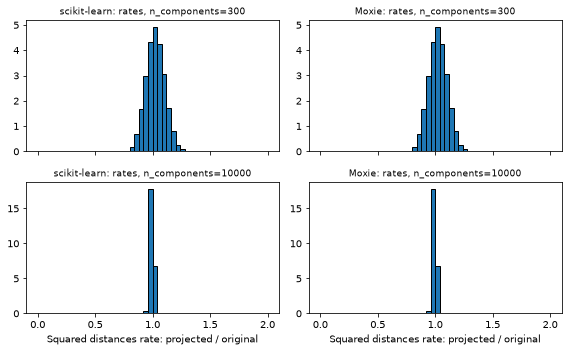

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"johnson_lindenstrauss_min_dim(n_samples array, eps)",PASS,"(45,)","(45,)",,,exact,0 mismatches,
"johnson_lindenstrauss_min_dim(n_samples, eps array)",PASS,"(500,)","(500,)",,,exact,0 mismatches,
SparseRandomProjection.components_ (k=300),PASS,"(300, 64)","(300, 64)",,,exact,0 mismatches,
SparseRandomProjection.fit_transform (k=300),PASS,"(300, 300)","(300, 300)",0,0,"rtol=1e-12, atol=1e-10",,"identical +-sqrt(s/k) components; only the summation order of the <=64-term dot products differs (SciPy CSR matmul vs native CSR loop), values reach ~1e2"
squared-distance rates (k=300),PASS,"(89700,)","(89700,)",7.11e-14,6.68e-14,"rtol=1e-09, atol=0",,ratios of distances computed from the projections above; rounding differences of ~1e-14 relative can grow by cancellation for near-duplicate digit pairs
SparseRandomProjection.components_ (k=1000),PASS,"(1000, 64)","(1000, 64)",,,exact,0 mismatches,
SparseRandomProjection.fit_transform (k=1000),PASS,"(300, 1000)","(300, 1000)",0,0,"rtol=1e-12, atol=1e-10",,"identical +-sqrt(s/k) components; only the summation order of the <=64-term dot products differs (SciPy CSR matmul vs native CSR loop), values reach ~1e2"
squared-distance rates (k=1000),PASS,"(89700,)","(89700,)",1.42e-13,1.33e-13,"rtol=1e-09, atol=0",,ratios of distances computed from the projections above; rounding differences of ~1e-14 relative can grow by cancellation for near-duplicate digit pairs
SparseRandomProjection.components_ (k=10000),PASS,"(10000, 64)","(10000, 64)",,,exact,0 mismatches,
SparseRandomProjection.fit_transform (k=10000),PASS,"(300, 10000)","(300, 10000)",0,0,"rtol=1e-12, atol=1e-10",,"identical +-sqrt(s/k) components; only the summation order of the <=64-term dot products differs (SciPy CSR matmul vs native CSR loop), values reach ~1e2"


In [10]:
mx = nb.results["jl_bound"]
csr = nb.results["jl_csr"]
inv = nb.results["jl_inverse"]
nz = euclidean_distances(data, squared=True).ravel() != 0
mx_rates = {}
for k in n_components_range:
    mx_rates[k] = euclidean_distances(mx[f"projected_{k}"], squared=True).ravel()[nz] / dists
moxie_nb.side_by_side(
    sklearn=np.array([[k, sk_rates[k].mean(), sk_rates[k].std()] for k in n_components_range]),
    moxie=np.array([[k, mx_rates[k].mean(), mx_rates[k].std()] for k in n_components_range]),
)
fig, axes = plt.subplots(2, 2, figsize=(8, 5), dpi=72, sharex=True)
for row, k in enumerate([300, 10000]):
    for col, (title, rates) in enumerate([("scikit-learn", sk_rates[k]), ("Moxie", mx_rates[k])]):
        axes[row, col].hist(rates, bins=50, range=(0.0, 2.0), edgecolor="k", density=True)
        axes[row, col].set_title(f"{title}: rates, n_components={k}", fontsize=9)
axes[1, 0].set_xlabel("Squared distances rate: projected / original"); axes[1, 1].set_xlabel("Squared distances rate: projected / original")
plt.tight_layout(); plt.show()

nb.compare("johnson_lindenstrauss_min_dim(n_samples array, eps)", np.concatenate(sk_bounds_by_eps), mx["bounds_by_eps"], exact=True)
nb.compare("johnson_lindenstrauss_min_dim(n_samples, eps array)", np.concatenate(sk_bounds_by_n), mx["bounds_by_n"], exact=True)
for k in n_components_range:
    nb.compare(f"SparseRandomProjection.components_ (k={k})", sk_components[k], mx[f"components_{k}"], exact=True)
    nb.compare(f"SparseRandomProjection.fit_transform (k={k})", sk_projected[k], mx[f"projected_{k}"], rtol=1e-12, atol=1e-10,
               reason="identical +-sqrt(s/k) components; only the summation order of the <=64-term dot products "
                      "differs (SciPy CSR matmul vs native CSR loop), values reach ~1e2")
    nb.compare(f"squared-distance rates (k={k})", sk_rates[k], mx_rates[k], rtol=1e-9, atol=0,
               reason="ratios of distances computed from the projections above; rounding differences of ~1e-14 "
                      "relative can grow by cancellation for near-duplicate digit pairs")
nb.compare("density_ (auto = 1/sqrt(64))", sk_density, mx["density"][0], exact=True)
nb.compare("n_components_, n_features_in_ (k=10000)", [10000, 64], mx["shape"], exact=True)
nb.compare("CSR input: sparse output when dense_output=False / True", [1, 0], csr["is_sparse"], exact=True)
nb.compare("CSR input: transform values (dense_output=False)", sk_csr_out.toarray(), csr["csr_out"], rtol=1e-12, atol=1e-10,
           reason="as for the dense input; CSR x CSR product summation order differs")
nb.compare("CSR input: transform values (dense_output=True)", sk_csr_dense_out, csr["csr_dense_out"], rtol=1e-12, atol=1e-10,
           reason="as above")
nb.compare("GaussianRandomProjection.components_ (k=30)", sk_g_components, inv["g_components"], rtol=1e-14, atol=1e-16,
           reason="same legacy MT19937 polar Gaussian draws times 1/sqrt(30); libm vs Mojo sqrt/log may differ by one ulp")
nb.compare("GaussianRandomProjection.inverse_components_", sk_g_inverse, inv["g_inverse"], rtol=1e-9, atol=1e-12,
           reason="pseudoinverse of a well-conditioned 30x64 matrix: native one-sided Jacobi SVD vs LAPACK gesdd")
nb.compare("GaussianRandomProjection.transform", sk_g_projected, inv["g_projected"], rtol=1e-12, atol=1e-10,
           reason="64-term dot products in a different summation order")
nb.compare("GaussianRandomProjection.inverse_transform (cached inverse)", sk_g_back, inv["g_back"], rtol=1e-8, atol=1e-9,
           reason="product of the transform with the pseudoinverse above; inherits its SVD rounding")
nb.compare("SparseRandomProjection.inverse_transform (computed per call)", sk_s_back, inv["s_back"], rtol=1e-8, atol=1e-9,
           reason="as above, for the densified sparse components")
nb.compare("get_feature_names_out", sk_names, list(inv["names"]), exact=True)
nb.note("DataDimensionalityWarning for n_components > n_features", "ADAPTED",
        f"sklearn warns ({sk_warnings[300]}); Moxie performs the same expansion silently (docs/random_projection/api.md, Explicit native limits)")
nb.note("random_state=None in the original example", "ADAPTED",
        "seeded with random_state=0 so the matrices are comparable; unseeded runs draw from different global streams by design")
nb.note("NDArray input to the projections", "GAP",
        "estimators accept only the family-local ProjectionMatrix; data is copied element-wise in the Mojo cells")
nb.note("make_pipeline(SparseRandomProjection, RidgeClassifier)", "GAP",
        f"sklearn training accuracy {sk_pipe_score:.3f}; Moxie fails to compile: ProjectionMatrix output cannot feed an NDArray estimator")
nb.report()
nb.assert_parity()